# Exercícios do Capítulo 1

## Histogramas

In [1]:
# Importamos a biblioteca pandas e damos-lhe a alcunha de 'pd' para ser mais rápido de escrever.
import pandas as pd
import matplotlib.pyplot as plt

# Passo 1: Definir o nome do ficheiro Excel.
# Substitui 'meu_ficheiro.xlsx' pelo nome real do teu ficheiro.
# Nota: O ficheiro deve estar na mesma pasta que este script Python.
nome_do_ficheiro = 'exerc.xlsx'

try:
    # Passo 2: Ler o ficheiro Excel e transformá-lo numa tabela pandas (DataFrame)
    # A função read_excel faz todo o trabalho pesado por nós.
    tabela = pd.read_excel(nome_do_ficheiro, header=None)
    dados_em_lista = tabela.values.flatten()
  

except FileNotFoundError:
    # Este bloco serve para o caso de o Python não encontrar o ficheiro.
    # É uma boa prática de programação prever pequenos erros.
    print(f"Erro: O ficheiro '{nome_do_ficheiro}' não foi encontrado.")
    print("Verifica se o nome está correto e se o ficheiro está na mesma pasta que o script.")

### 1.2 Algumas cidades são mais ventosas do que outras? Chicago merece o apelido de "Cidade dos Ventos"? Abaixo estão as velocidades médias do vento (em milhas por hora) para 45 cidades selecionadas dos EUA:

In [2]:
dados_em_lista

array([ 8.9, 12.4,  8.6, 11.3,  9.2,  8.8, 35.1,  6.2,  7. ,  7.1, 11.8,
       10.7,  7.6,  9.1,  9.2,  8.2,  9. ,  8.7,  9.1, 10.9, 10.3,  9.6,
        7.8, 11.5,  9.3,  7.9,  8.8,  8.8, 12.7,  8.4,  7.8,  5.7, 10.5,
       10.5,  9.6,  8.9, 10.2, 10.3,  7.7, 10.6,  8.3,  8.8,  9.5,  8.8,
        9.4])

#### a) Construa um histograma de frequência relativa para esses dados. (Escolha os limites de classe sem incluir o valor 35,1 no intervalo de valores.)

In [4]:
# Estamos a dar o nome 'Valores' para esta nossa nova e única coluna
dados = pd.DataFrame(dados_em_lista, columns=['Valores'])

# Passo 4: Limpar possíveis buracos (células vazias) e reorganizar a contagem das linhas
dados = dados.dropna().reset_index(drop=True)

# Exibir os primeiros 15 resultados para confirmar que os dados 8.9, 12.4, etc., não foram perdidos!
dados.head(15)

,Valores
0,8.9
1,12.4
2,8.6
3,11.3
4,9.2
5,8.8
6,35.1
7,6.2
8,7.0
9,7.1


In [ ]:
media = dados.mean()      # Resultado: 2.3333...
mediana = dados.median()  # Resultado: 2.5
moda = dados.mode()       # Resultado: 1 e 3 (identifica que a amostra é bimodal)

# O Pandas calcula a variância e o desvio padrão AMOSTRAL por padrão (divide por n-1)
variancia = dados.var()     # Resultado: 1.4666... (Exatamente os 44/30 teóricos)
desvio_padrao = dados.std() # Resultado: 1.2110...
media = dados.mean()

# Amplitude (Máximo - Mínimo)
amplitude = dados.max() - dados.min()

print(f"Media: {media}")
print(f"mediana: {mediana}")
print(f"moda: {moda}")
print(f"variancia: {variancia}")
print(f"desvio_padrao: {desvio_padrao}")
print(f"amplitude: {amplitude}")

Media: Valores    9.791111
dtype: float64
mediana: Valores    9.1
dtype: float64
moda:    Valores
0      8.8
variancia: Valores    17.123101
dtype: float64
desvio_padrao: Valores    4.138007
dtype: float64
amplitude: Valores    29.4
dtype: float64


#### b) Calcule o intervalo y ± ks para k = 1, 2 e 3. Conte o número de medições que se enquadram em cada intervalo e compare esse resultado com o número que você esperaria de acordo com a regra empírica.



In [14]:
inteiros = [1,2,3]

for inteiro in inteiros:
    limite_inferior = media - desvio_padrao*inteiro
    limite_superior = media + desvio_padrao*inteiro
    print(f"Intervalo para k = {inteiro} é igual a ({ limite_inferior},{ limite_superior})")
    


Intervalo para k = 1 é igual a (Valores    5.653104
dtype: float64,Valores    13.929118
dtype: float64)
Intervalo para k = 2 é igual a (Valores    1.515097
dtype: float64,Valores    18.067125
dtype: float64)
Intervalo para k = 3 é igual a (Valores   -2.62291
dtype: float64,Valores    22.205132
dtype: float64)


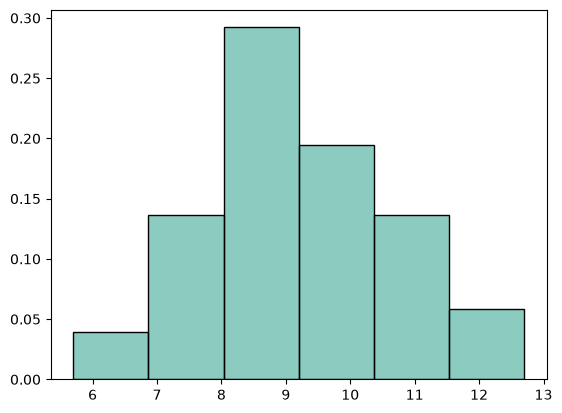

In [48]:
# color: cor ou sequência A cor (ou cores) das barras.
plt.hist(dados, bins=6, range=(min_dados,max_dados), density=True, color= (0.1, 0.6, 0.5, 0.5),  edgecolor='black')
plt.show()


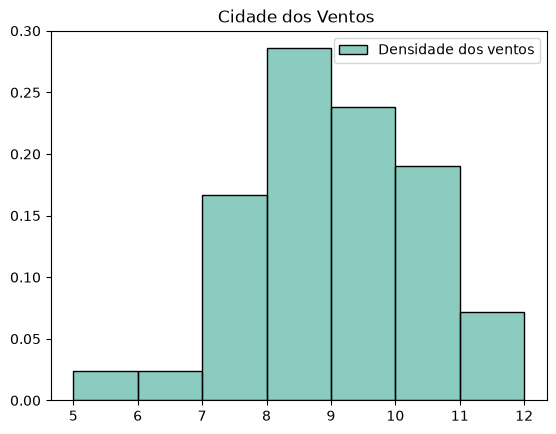

In [49]:
# label: Rótulo da série para aparecer na legenda (plt.legend).
plt.hist(dados, bins=[5,6,7,8,9,10,11,12], range=(min_dados,max_dados), density=True, color= (0.1, 0.6, 0.5, 0.5), label= "Densidade dos ventos",  edgecolor='black')
plt.legend()
plt.title("Cidade dos Ventos ")
plt.show()

#### 1.4 As 40 principais ações negociadas no mercado de balcão (OTC), classificadas pela porcentagem de ações em circulação negociadas em um dia do ano passado, são as seguintes:

In [81]:
dados = { "Ações" : [
    11.88, 6.27, 5.49, 4.81, 4.40, 3.78, 3.44, 3.11, 2.88, 2.68,
    7.99, 6.07, 5.26, 4.79, 4.05, 3.69, 3.36, 3.03, 2.74, 2.63,
    7.15, 5.98, 5.07, 4.55, 3.94, 3.62, 3.26, 2.99, 2.74, 2.62,
    7.13, 5.91, 4.94, 4.43, 3.93, 3.48, 3.20, 2.89, 2.69, 2.61
]}

In [85]:
dados = pd.DataFrame(dados)
dados.head()

,Ações
0,11.88
1,6.27
2,5.49
3,4.81
4,4.40


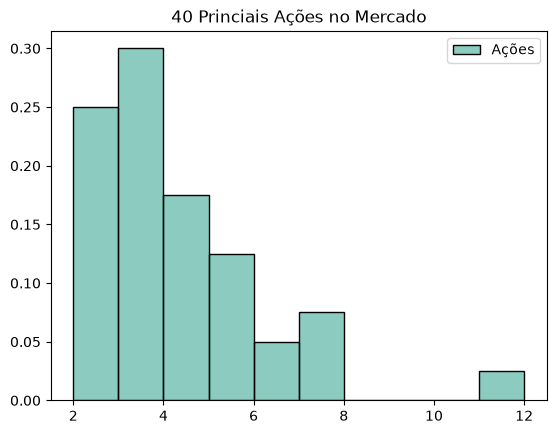

In [87]:
plt.hist(dados, bins=[2,3,4,5,6,7,8,9,10,11,12], range=(min_dados,max_dados), density=True, color= (0.1, 0.6, 0.5, 0.5), label= "Ações",  edgecolor='black')
plt.legend()
plt.title("40 Princiais Ações no Mercado")
plt.show()

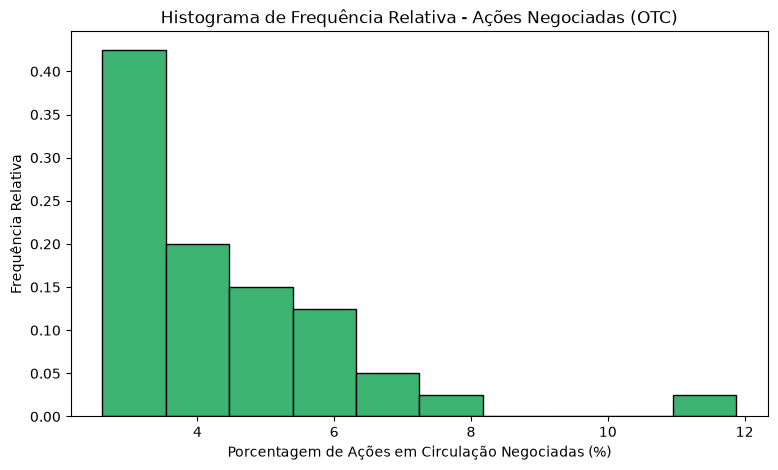


--- RESULTADOS DA ALÍNEA B ---
Total de ações na lista: 40
Ações que negociaram mais de 4%: 18
Proporção: 0.45 (ou 45.0%)


In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Os nossos dados limpos
dados = [
    11.88, 6.27, 5.49, 4.81, 4.40, 3.78, 3.44, 3.11, 2.88, 2.68,
    7.99, 6.07, 5.26, 4.79, 4.05, 3.69, 3.36, 3.03, 2.74, 2.63,
    7.15, 5.98, 5.07, 4.55, 3.94, 3.62, 3.26, 2.99, 2.74, 2.62,
    7.13, 5.91, 4.94, 4.43, 3.93, 3.48, 3.20, 2.89, 2.69, 2.61
]

# Transformar numa tabela do Pandas
tabela = pd.DataFrame(dados, columns=['Porcentagem_Negociada'])


# ==========================================
# RESPOSTA DA ALÍNEA A: Histograma
# ==========================================

# Criar pesos para que o eixo Y mostre a Frequência Relativa (proporção) em vez da contagem
pesos = np.ones_like(tabela['Porcentagem_Negociada']) / len(tabela)

# Desenhar o gráfico
plt.figure(figsize=(9, 5))
plt.hist(
    tabela['Porcentagem_Negociada'], 
    bins=10, # 10 divisões costuma ser um bom número para 40 dados
    weights=pesos, 
    edgecolor='black', 
    color='mediumseagreen'
)

# Estética do Gráfico
plt.title('Histograma de Frequência Relativa - Ações Negociadas (OTC)')
plt.xlabel('Porcentagem de Ações em Circulação Negociadas (%)')
plt.ylabel('Frequência Relativa')
plt.show()


# ==========================================
# RESPOSTA DA ALÍNEA B: Proporção > 4%
# ==========================================

# Filtrar as ações que representaram MAIS de 4% (> 4)
acoes_acima_de_4 = tabela[tabela['Porcentagem_Negociada'] > 4.0]

# Contar quantas ações passaram no filtro
quantidade = len(acoes_acima_de_4)
total_acoes = len(tabela)

# Calcular a proporção (fração)
proporcao = quantidade / total_acoes

print("\n--- RESULTADOS DA ALÍNEA B ---")
print(f"Total de ações na lista: {total_acoes}")
print(f"Ações que negociaram mais de 4%: {quantidade}")
print(f"Proporção: {proporcao} (ou {proporcao * 100:.1f}%)")

# Atividade Prática Independente

#### Fazer um Histograma com uma quantidade maior dos dados

In [30]:
# importando Bilbiotecas

import pandas as pd
import matplotlib.pyplot as plt



In [14]:
# Carregando dados

acidentes_envolvidos = pd.read_excel("acidentes.xlsx", sheet_name="envolvidos" )

acidentes_envolvidos.head()

,num_boletim,numero_envolvido,condutor,codigo_severidade,desc_severidade,sexo,cinto_seguranca,Embreagues,Idade,categoria_habilitacao,descricao_habilitacao,especie_veiculo,pedestre,passageiro,Data,Hora
0,2019051653049001,40,N,1,NAO FATAL,F,SIM,NÃO,52.0,NaN,NaN,ONIBUS,N,S,2019-10-21,18:36:00
1,2019051653049001,39,N,1,NAO FATAL,M,SIM,NÃO,29.0,NaN,NaN,ONIBUS,N,S,2019-10-21,18:36:00
2,2019051653049001,38,N,1,NAO FATAL,M,SIM,NÃO,43.0,NaN,NaN,ONIBUS,N,S,2019-10-21,18:36:00
3,2019051653049001,37,N,1,NAO FATAL,M,SIM,NÃO,51.0,NaN,NaN,ONIBUS,N,S,2019-10-21,18:36:00
4,2019051653049001,36,N,1,NAO FATAL,M,SIM,NÃO,31.0,NaN,NaN,ONIBUS,N,S,2019-10-21,18:36:00


#### Fase 1: Diagnóstico e Inspeção (O Raio-X) Antes de alterar qualquer célula, é necessário compreender a anatomia e os defeitos do arquivo importado.

In [15]:
# Visão Geral: Execute df.info() para checar imediatamente a quantidade de colunas, os tipos de dados nativos que o Pandas inferiu e a contagem de valores não nulos.
acidentes_envolvidos.info()

<class 'pandas.DataFrame'>
RangeIndex: 154713 entries, 0 to 154712
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   num_boletim            154713 non-null  str           
 1   numero_envolvido       154713 non-null  int64         
 2   condutor               154713 non-null  object        
 3   codigo_severidade      154713 non-null  int64         
 4   desc_severidade        154713 non-null  str           
 5   sexo                   154713 non-null  object        
 6   cinto_seguranca        154713 non-null  str           
 7   Embreagues             154713 non-null  str           
 8   Idade                  154711 non-null  float64       
 9   categoria_habilitacao  107199 non-null  str           
 10  descricao_habilitacao  108198 non-null  str           
 11  especie_veiculo        143297 non-null  str           
 12  pedestre               147220 non-null  str           


In [16]:
# Estatística Descritiva: Rode df.describe(). Isso permite bater o olho e identificar anomalias numéricas imediatas (ex: idades negativas ou preços zerados).

acidentes_envolvidos.describe()

,numero_envolvido,codigo_severidade,Idade,Data
count,154713.000000,154713.000000,154711.000000,154713
mean,1.784168,1.775578,34.015409,2018-12-03 05:42:27.175738
min,1.000000,0.000000,0.000000,2016-01-01 00:00:00
25%,1.000000,1.000000,24.000000,2017-06-06 00:00:00
50%,2.000000,1.000000,33.000000,2018-12-04 00:00:00
75%,2.000000,3.000000,44.000000,2020-05-06 00:00:00
max,40.000000,3.000000,121.000000,2021-12-31 00:00:00
std,1.070734,1.034686,16.695134,NaN


In [17]:
# Mapeamento de Nulos: Use df.isnull().sum() para quantificar exatamente quantas linhas estão vazias em cada variável.
acidentes_envolvidos.isnull().sum()

num_boletim                  0
numero_envolvido             0
condutor                     0
codigo_severidade            0
desc_severidade              0
sexo                         0
cinto_seguranca              0
Embreagues                   0
Idade                        2
categoria_habilitacao    47514
descricao_habilitacao    46515
especie_veiculo          11416
pedestre                  7493
passageiro                7105
Data                         0
Hora                         0
dtype: int64

In [18]:
# 1. Explorando a causa: verificando se os nulos estão associados a pedestres/passageiros
nulos_habilitacao = acidentes_envolvidos[acidentes_envolvidos['categoria_habilitacao'].isnull()]
print(nulos_habilitacao[['condutor', 'pedestre', 'passageiro']].value_counts())

condutor  pedestre  passageiro
S         N         N             26942
N         N         S             12787
          S         N              6933
          N         N                96
Name: count, dtype: int64


In [21]:
# 1. Explorando a causa: verificando se os nulos estão associados a pedestres/passageiros
nulos_descricao_habilitacao = acidentes_envolvidos[acidentes_envolvidos['descricao_habilitacao'].isnull()]
print(nulos_habilitacao[['condutor', 'pedestre', 'passageiro']].value_counts())

condutor  pedestre  passageiro
S         N         N             26942
N         N         S             12787
          S         N              6933
          N         N                96
Name: count, dtype: int64


In [34]:
# Preenchendo os nulos com uma categoria que reflete a realidade encontrada
acidentes_envolvidos['categoria_habilitacao'] = acidentes_envolvidos['categoria_habilitacao'].fillna('Não Informado / Sem CNH')
acidentes_envolvidos['descricao_habilitacao'] = acidentes_envolvidos['descricao_habilitacao'].fillna('Não Informado / Sem CNH')
acidentes_envolvidos['especie_veiculo'] = acidentes_envolvidos['especie_veiculo'].fillna('Não Informado / Não se aplica')
acidentes_envolvidos['pedestre'] = acidentes_envolvidos['pedestre'].fillna('Não Informado / Não se aplica')
acidentes_envolvidos['passageiro'] = acidentes_envolvidos['passageiro'].fillna('Não Informado / Não se aplica')
acidentes_envolvidos.isnull().sum()

num_boletim              0
numero_envolvido         0
condutor                 0
codigo_severidade        0
desc_severidade          0
sexo                     0
cinto_seguranca          0
Embreagues               0
Idade                    2
categoria_habilitacao    0
descricao_habilitacao    0
especie_veiculo          0
pedestre                 0
passageiro               0
Data                     0
Hora                     0
dtype: int64

(array([1.3063e+04, 2.8921e+04, 4.9483e+04, 3.4714e+04, 1.8708e+04,
        7.2540e+03, 2.2450e+03, 2.9900e+02, 8.0000e+00, 1.6000e+01]),
 array([  0. ,  12.1,  24.2,  36.3,  48.4,  60.5,  72.6,  84.7,  96.8,
        108.9, 121. ]),
 <BarContainer object of 10 artists>)

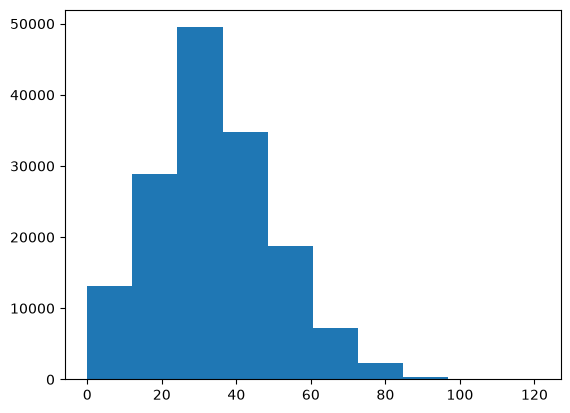

In [33]:
# Criando o Histograma

plt.hist(acidentes_envolvidos['Idade'])

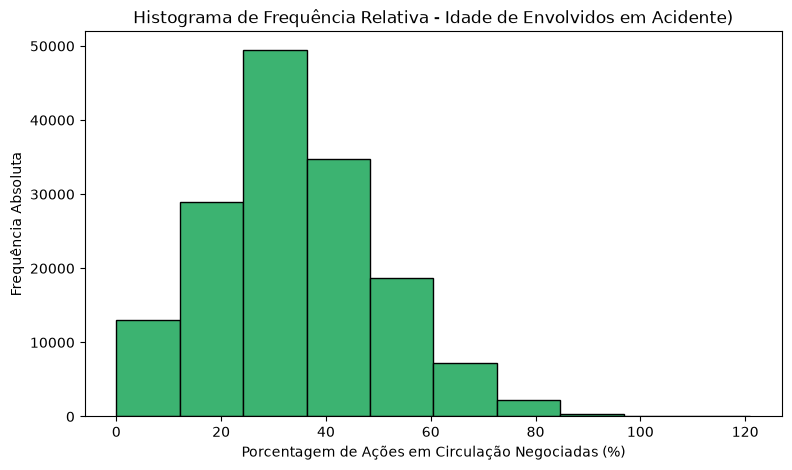

In [ ]:
plt.figure(figsize=(9, 5))
plt.hist(
    acidentes_envolvidos['Idade'], 
    bins=10, # 10 divisões costuma ser um bom número para 40 dados
  
    edgecolor='black', 
    color='mediumseagreen'
)

# Estética do Gráfico
plt.title('Histograma de Frequência Absoluta - Idade de Envolvidos em Acidente)')
plt.xlabel('Idaededos Envolvidos')
plt.ylabel('Frequência Absoluta')
plt.show()

#### 1.24 A corrida aquática tem sido sugerida como um método de condicionamento cardiovascular para atletas lesionados e outras pessoas que desejam um programa de aeróbica de baixo impacto. Em um estudo para investigar a relação entre a cadência do exercício e a frequência cardíaca, ¹ as frequências cardíacas de 20 voluntários saudáveis ​​foram medidas a uma cadência de 48 ciclos por minuto (um ciclo consistia em dois passos). Os dados são os seguintes:

#### 87 109 79 80 96 95 90 92 96 98 101 91 78 112 94 98 94 107 81 96

In [24]:
frequencia = [87,109,79,80,96,95,90,92,96,98,101,91,78,112,94,98,94,107,81,96]
print("Máximo: ", max(frequencia))
print("Mínimo: ", min(frequencia))

desvio_padrao = (max(frequencia) - min(frequencia))/4

print("Desvio Padrão: ", desvio_padrao)


Máximo:  112
Mínimo:  78
Desvio Padrão:  8.5


(array([4., 3., 9., 1., 3.]),
 array([ 78. ,  84.8,  91.6,  98.4, 105.2, 112. ]),
 <BarContainer object of 5 artists>)

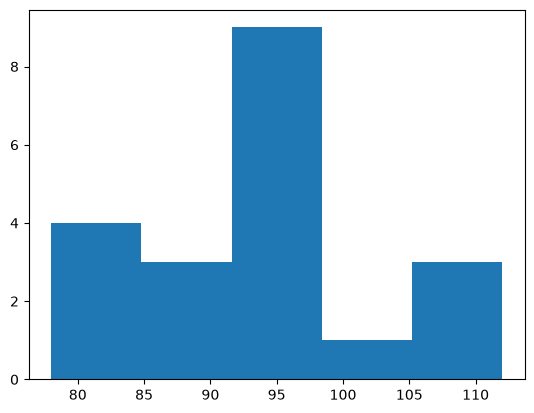

In [26]:
plt.hist(frequencia, bins=5)

In [35]:
frequencia = pd.DataFrame(frequencia)
desvio_padrao = frequencia.std() # Resultado: 1.2110...
media = frequencia.mean()

print(f"Media: {media}, desvio padrão: {desvio_padrao}")

frequencia

Media: 0    93.7
dtype: float64, desvio padrão: 0    9.553726
dtype: float64


,0
0,87
1,109
2,79
3,80
4,96
5,95
6,90
7,92
8,96
9,98


In [32]:
minimo_1 = media - desvio_padrao*1
maximo_1 = media + desvio_padrao*1
minimo_2 = media - desvio_padrao*2
maximo_2 = media + desvio_padrao*2
minimo_3 = media - desvio_padrao*3
maximo_3 = media + desvio_padrao*3

print(f"Intervalo 1: ({minimo_1},{maximo_1}), Intervalo 2: ({minimo_2},{maximo_2}), Intervalo 3: ({minimo_3},{maximo_3}) ")


Intervalo 1: (0    84.146274
dtype: float64,0    103.253726
dtype: float64), Intervalo 2: (0    74.592548
dtype: float64,0    112.807452
dtype: float64), Intervalo 3: (0    65.038821
dtype: float64,0    122.361179
dtype: float64) 


In [36]:
frequencia.sort_values(0)

,0
12,78
2,79
3,80
18,81
0,87
6,90
11,91
7,92
16,94
14,94


#### 1.25 Os dados a seguir fornecem os tempos até a falha para n = 88 transmissores-receptores de rádio:

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# Lê os dados tabulares armazenados no seu "Ctrl+C"
tempos_falha = pd.read_clipboard(header=None)

display(tempos_falha.head())

,0,1,2,3,4,5,6,7
0,16,224,16,80,96,536,400,80
1,392,576,128,56,656,224,40,32
2,358,384,256,246,328,464,448,716
3,304,16,72,8,80,72,56,608
4,108,194,136,224,80,16,424,264


In [20]:
# Salvar a tabela extraída e limpa para análises futuras no seu diretório
tempos_falha.to_csv('tempos_falhas.csv', index=False)

##### a Use o intervalo para aproximar s para os n = 88 tempos até a falha.

In [21]:
tempos_falha = pd.read_csv('tempos_falhas.csv')
tempos_falha

,0,1,2,3,4,5,6,7
0,16,224,16,80,96,536,400,80
1,392,576,128,56,656,224,40,32
2,358,384,256,246,328,464,448,716
3,304,16,72,8,80,72,56,608
4,108,194,136,224,80,16,424,264
5,156,216,168,184,552,72,184,240
6,438,120,308,32,272,152,328,480
7,60,208,340,104,72,168,40,152
8,360,232,40,112,112,288,168,352
9,56,72,64,40,184,264,96,224


(array([21., 14., 18., 13.,  8.,  4.,  4.,  2.,  2.,  2.]),
 array([  8. ,  78.8, 149.6, 220.4, 291.2, 362. , 432.8, 503.6, 574.4,
        645.2, 716. ]),
 <BarContainer object of 10 artists>)

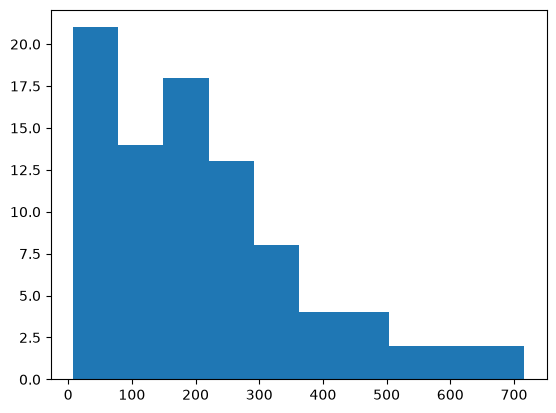

In [ ]:
tempos_falha = tempos_falha.stack().reset_index(drop=True)
plt.hist(tempos_falha)


In [26]:
print(min(tempos_falha))
print(max(tempos_falha))

8
716


In [29]:
desvio_aproximado = (max(tempos_falha)-min(tempos_falha))/4
desvio_aproximado

177.0

In [33]:
media = tempos_falha.mean()
print(media)

210.79545454545453


In [34]:
desvio_padrao = tempos_falha.std()
print(desvio_padrao)

162.17275867809082


In [35]:
meus_intervalos = [
    media - (2 * desvio_padrao),
    media - (1 * desvio_padrao),
    media,           # O centro exato do gráfico
    media + (1 * desvio_padrao),
    media + (2 * desvio_padrao)
]

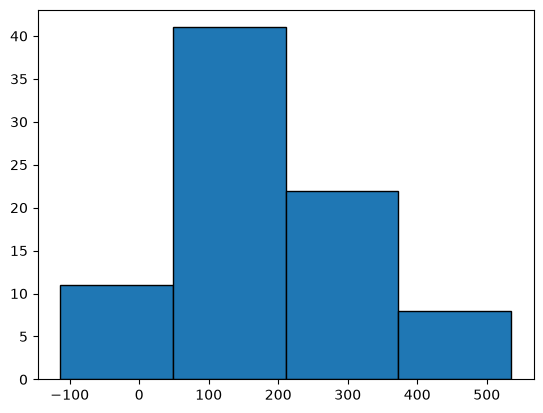

In [37]:
plt.hist(tempos_falha, bins = meus_intervalos, edgecolor='black')
plt.show()
